# Player bounding

Load 20 frames from a SportsMOT training sequence for player-detection work.

In [1]:
from io import BytesIO
from pathlib import Path
import tarfile

from PIL import Image

archive_candidates = [
    Path("data/sportsmot_download/dataset/train.tar"),
    Path("../data/sportsmot_download/dataset/train.tar"),
]
archive = next((path for path in archive_candidates if path.exists()), None)

if archive is None:
    raise FileNotFoundError("Could not find data/sportsmot_download/dataset/train.tar")

sequence = "train/v_-6Os86HzwCs_c001"

with tarfile.open(archive, "r") as tar:
    selected = sorted(
        (member for member in tar.getmembers()
         if member.isfile()
         and member.name.startswith(sequence + "/img1/")
         and member.name.endswith(".jpg")
         and not member.name.rsplit("/", 1)[-1].startswith("._")),
        key=lambda member: member.name,
    )[:20]

    images = [
        Image.open(BytesIO(tar.extractfile(member).read())).convert("RGB")
        for member in selected
    ]

print(f"Loaded {len(images)} frames from {sequence}")
print(f"First frame: {selected[0].name}")

Loaded 20 frames from train/v_-6Os86HzwCs_c001
First frame: train/v_-6Os86HzwCs_c001/img1/000001.jpg


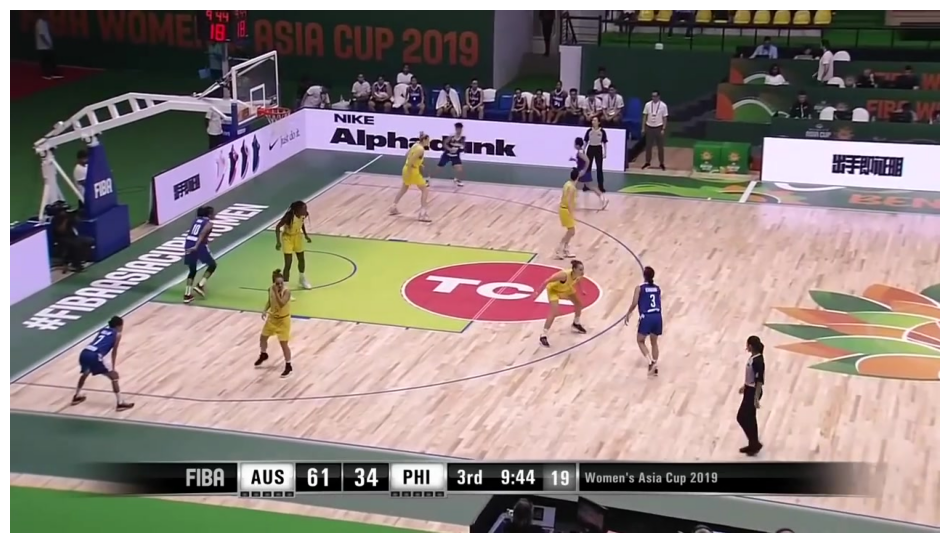

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
plt.imshow(images[0])
plt.axis("off")
plt.show()

work here